In [1]:
import yfinance as yf
import datetime as dt
from matplotlib import pyplot as plt

In [2]:
START = dt.date(2000, 1, 1)
END = dt.date.today()
STOCKS = ["AAPL", "MSFT"]

In [3]:
df = yf.download(STOCKS, start=START, end=END, multi_level_index=False)

[*********************100%***********************]  2 of 2 completed


In [4]:
df = df.reset_index()

In [5]:
df.head()

Price        Date     Close                 High                  Low  \
Ticker                 AAPL       MSFT      AAPL       MSFT      AAPL   
0      2000-01-03  0.837002  35.377007  0.841208  36.002980  0.760359   
1      2000-01-04  0.766435  34.181957  0.827188  35.547718  0.756620   
2      2000-01-05  0.777650  34.542393  0.826721  35.320118  0.770173   
3      2000-01-06  0.710353  33.385277  0.800082  34.561349  0.710353   
4      2000-01-07  0.744002  33.821568  0.755219  34.068163  0.714093   

Price                  Open                Volume            
Ticker       MSFT      AAPL       MSFT       AAPL      MSFT  
0       33.992277  0.784193  35.623602  535796800  53228400  
1       34.068144  0.809430  34.466491  512377600  54119000  
2       33.195600  0.775781  33.726729  778321600  64059600  
3       32.892085  0.793540  34.049189  767972800  54976600  
4       32.569619  0.721570  32.967967  460734400  62013600

In [6]:
df[["Date", "Close"]]

Price        Date       Close            
Ticker                   AAPL        MSFT
0      2000-01-03    0.837002   35.377007
1      2000-01-04    0.766435   34.181957
2      2000-01-05    0.777650   34.542393
3      2000-01-06    0.710353   33.385277
4      2000-01-07    0.744002   33.821568
...           ...         ...         ...
6735   2026-10-14  342.959991  533.690002
6736   2026-10-15  342.000000  539.440002
6737   2026-10-16  343.459991  529.049988
6738   2026-10-19  342.940002  533.520020
6739   2026-10-20  339.500000  531.869995

[6740 rows x 3 columns]

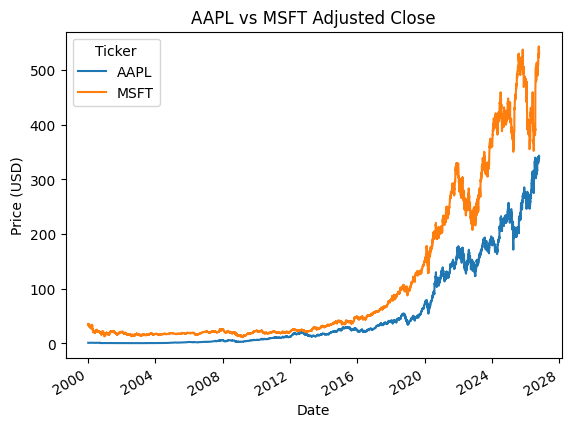

In [7]:
close = df.set_index("Date")["Close"]

ax = close.plot()
ax.set_title("AAPL vs MSFT Adjusted Close")
ax.set_xlabel("Date")
ax.set_ylabel("Price (USD)")
plt.show()

In [8]:
daily_return = close.pct_change().dropna()
daily_return

Ticker,AAPL,MSFT
Date,,
2000-01-04,-0.084310,-0.033780
2000-01-05,0.014633,0.010545
2000-01-06,-0.086539,-0.033498
2000-01-07,0.047369,0.013068
2000-01-10,-0.017588,0.007291
...,...,...
2026-10-14,0.004952,-0.017959
2026-10-15,-0.002799,0.010774
2026-10-16,0.004269,-0.019261


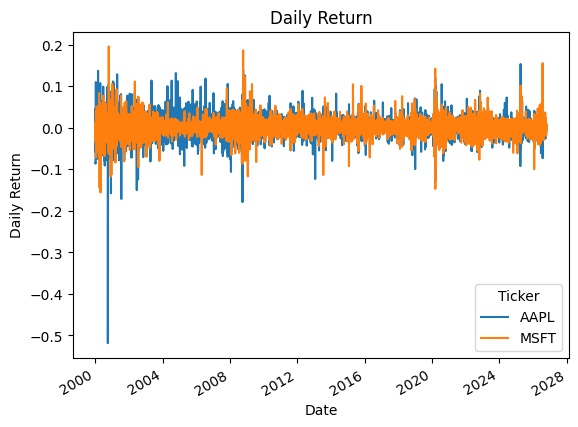

In [9]:
ax = daily_return.plot()
ax.set_title("Daily Return")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Return")
plt.show()

In [10]:
daily_cumulative_return = (daily_return + 1).cumprod()
daily_cumulative_return

Ticker,AAPL,MSFT
Date,,
2000-01-04,0.915690,0.966220
2000-01-05,0.929089,0.976408
2000-01-06,0.848687,0.943700
2000-01-07,0.888889,0.956032
2000-01-10,0.873255,0.963003
...,...,...
2026-10-14,409.747891,15.085787
2026-10-15,408.600951,15.248322
2026-10-16,410.345261,14.954628


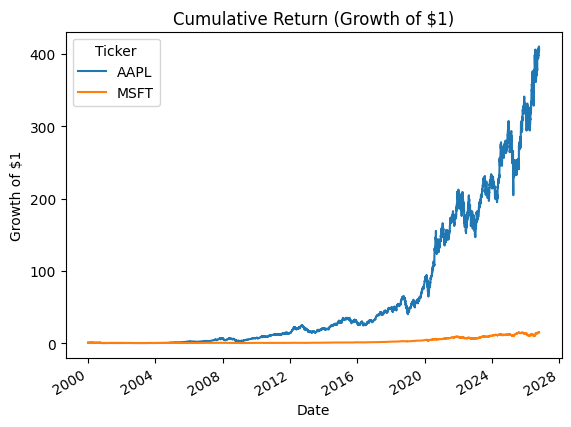

In [11]:
ax = daily_cumulative_return.plot()
ax.set_title("Cumulative Return (Growth of $1)")
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
plt.show()